# 04 — Model Evaluation and Selection

## Mục tiêu

Notebook này thực hiện:

1. Chuẩn bị lại dữ liệu cho bài toán phân loại `Purchase_Level`.
2. Giữ nguyên Train/Test Split với `random_state=42`.
3. Đánh giá 4 mô hình bằng Stratified 5-Fold Cross-Validation:
   - Logistic Regression
   - Random Forest
   - XGBoost
   - Neural Network (MLP)
4. So sánh độ chính xác và độ ổn định của các mô hình.
5. Chọn mô hình phù hợp để thực hiện Hyperparameter Tuning.

> Test set được giữ riêng và không sử dụng trong Cross-Validation hoặc Hyperparameter Tuning.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    LabelEncoder,
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

RANDOM_STATE = 42
N_SPLITS = 5

In [2]:
DATA_PATH = Path(
    "../data/processed/ecommerce_customer_behavior_with_target.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nPurchase_Level distribution:")
print(df["Purchase_Level"].value_counts())

df.head()

Dataset shape: (49960, 26)

Purchase_Level distribution:
Purchase_Level
Low       18953
High      15877
Medium    15130
Name: count, dtype: int64


,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter,Purchase_Level
0,43.0,Male,France,Marseille,2.9,14.0,27.4,6.0,50.6,3.0,...,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1,Low
1,36.0,Male,UK,Manchester,1.6,15.0,42.7,10.3,37.7,1.0,...,7.0,3.0,27.6,23.3,3.0,1067.47,3028.0,0,Q4,High
2,45.0,Female,Canada,Vancouver,2.9,10.0,24.8,1.6,70.9,1.0,...,4.0,1.0,27.6,8.8,2.0,1289.75,2317.0,0,Q4,Low
3,56.0,Female,USA,New York,2.6,10.0,38.4,14.8,41.7,9.0,...,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1,Medium
4,35.0,Male,India,Delhi,3.1,29.0,51.4,8.4,19.1,9.0,...,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4,High


In [3]:
TARGET = "Purchase_Level"

LEAKAGE_FEATURES = [
    "Total_Purchases",
]

X = df.drop(
    columns=[TARGET] + LEAKAGE_FEATURES
)

y = df[TARGET].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nExcluded leakage features:")
print(LEAKAGE_FEATURES)

print("\nTotal_Purchases excluded:")
print("Total_Purchases" not in X.columns)

print("\nLifetime_Value included:")
print("Lifetime_Value" in X.columns)

print("\nNumber of input features:")
print(X.shape[1])

X shape: (49960, 24)
y shape: (49960,)

Excluded leakage features:
['Total_Purchases']

Total_Purchases excluded:
True

Lifetime_Value included:
True

Number of input features:
24


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)

distribution = pd.DataFrame({
    "Train (%)": y_train.value_counts(normalize=True) * 100,
    "Test (%)": y_test.value_counts(normalize=True) * 100,
}).round(2)

display(distribution)

Train shape: (39968, 24)
Test shape : (9992, 24)


,Train (%),Test (%)
Purchase_Level,,
Low,37.94,37.94
High,31.78,31.78
Medium,30.28,30.28


In [5]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numeric features     :", len(numeric_features))
print("Categorical features :", len(categorical_features))
print("Total                :", len(numeric_features) + len(categorical_features))

print("\nCategorical:")
print(categorical_features)

Numeric features     : 20
Categorical features : 4
Total                : 24

Categorical:
['Gender', 'Country', 'City', 'Signup_Quarter']


In [6]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_features,
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features,
        ),
    ]
)

print(preprocessor)

ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                 ['Age', 'Membership_Years', 'Login_Frequency',
                                  'Session_Duration_Avg', 'Pages_Per_Session',
                                  'Cart_Abandonment_Rate', 'Wishlist_Items',
                                  'Average_Order_Value',
                                  'Days_Since_Last_Purchase',
                                  'Discount_Usage_Rate', 'Returns_Rate',
                                  'Email_Open_Rate', 'Customer_Service_Calls',
                                  'Product_Reviews_Written',
                                  'Social_Media_Engagement_Score',
                                  'Mobile_App_Usage',
                                  'Payment_Method_Diversity', 'Lifetime_Value',
                                  'Credit_Balance', 'Churned']),
                                ('categorical',
                                 OneHotEncoder(handle_un

In [7]:
CLASS_ORDER = ["Low", "Medium", "High"]

class_to_int = {
    "Low": 0,
    "Medium": 1,
    "High": 2,
}

y_train_encoded = y_train.map(class_to_int)

print("Target encoding:")
for label, value in class_to_int.items():
    print(f"{label:6s} -> {value}")

print("\nEncoded distribution:")
print(y_train_encoded.value_counts().sort_index())

print("\nMissing after encoding:", y_train_encoded.isna().sum())

Target encoding:
Low    -> 0
Medium -> 1
High   -> 2

Encoded distribution:
Purchase_Level
0    15162
1    12104
2    12702
Name: count, dtype: int64

Missing after encoding: 0


In [8]:
cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

print("Cross-validation:")
print("Method       : StratifiedKFold")
print(f"Number folds : {N_SPLITS}")
print("Shuffle      : True")
print(f"Random state : {RANDOM_STATE}")

Cross-validation:
Method       : StratifiedKFold
Number folds : 5
Shuffle      : True
Random state : 42


In [9]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE,
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),

    "Neural Network": MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        alpha=0.0001,
        batch_size=256,
        learning_rate_init=0.001,
        max_iter=300,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=15,
        random_state=RANDOM_STATE,
    ),
}

for name, model in models.items():
    print(f"{name}:")
    print(model)
    print("-" * 60)

Logistic Regression:
LogisticRegression(max_iter=2000, random_state=42)
------------------------------------------------------------
Random Forest:
RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)
------------------------------------------------------------
XGBoost:
XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estim

In [10]:
scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
}

print("Evaluation metrics:")
for metric in scoring:
    print("-", metric)

Evaluation metrics:
- accuracy
- precision_macro
- recall_macro
- f1_macro


In [11]:
cv_results = []
fold_results = []

for model_name, model in models.items():

    print("=" * 70)
    print(f"Running: {model_name}")
    print("=" * 70)

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model),
    ])

    start_time = time.time()

    scores = cross_validate(
        pipeline,
        X_train,
        y_train_encoded,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=1,
    )

    elapsed_time = time.time() - start_time

    cv_results.append({
        "Model": model_name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Macro Precision Mean": scores["test_precision_macro"].mean(),
        "Macro Precision Std": scores["test_precision_macro"].std(),
        "Macro Recall Mean": scores["test_recall_macro"].mean(),
        "Macro Recall Std": scores["test_recall_macro"].std(),
        "Macro F1 Mean": scores["test_f1_macro"].mean(),
        "Macro F1 Std": scores["test_f1_macro"].std(),
        "CV Time (s)": elapsed_time,
    })

    for fold in range(N_SPLITS):
        fold_results.append({
            "Model": model_name,
            "Fold": fold + 1,
            "Accuracy": scores["test_accuracy"][fold],
            "Macro Precision": scores["test_precision_macro"][fold],
            "Macro Recall": scores["test_recall_macro"][fold],
            "Macro F1": scores["test_f1_macro"][fold],
        })

    print(
        f"Macro F1: "
        f"{scores['test_f1_macro'].mean():.4f} "
        f"± {scores['test_f1_macro'].std():.4f}"
    )

    print(
        f"Accuracy: "
        f"{scores['test_accuracy'].mean():.4f} "
        f"± {scores['test_accuracy'].std():.4f}"
    )

    print(f"CV time: {elapsed_time:.2f}s")

Running: Logistic Regression


Macro F1: 0.7957 ± 0.0130
Accuracy: 0.8015 ± 0.0133
CV time: 1.92s
Running: Random Forest


Macro F1: 0.7951 ± 0.0045
Accuracy: 0.8008 ± 0.0045
CV time: 13.76s
Running: XGBoost


Macro F1: 0.8626 ± 0.0021
Accuracy: 0.8666 ± 0.0021
CV time: 8.93s
Running: Neural Network


Macro F1: 0.8589 ± 0.0038
Accuracy: 0.8633 ± 0.0038
CV time: 30.70s


In [12]:
cv_summary = pd.DataFrame(cv_results)

cv_summary = cv_summary.sort_values(
    by="Macro F1 Mean",
    ascending=False,
).reset_index(drop=True)

display(cv_summary.round(4))

,Model,Accuracy Mean,Accuracy Std,Macro Precision Mean,Macro Precision Std,Macro Recall Mean,Macro Recall Std,Macro F1 Mean,Macro F1 Std,CV Time (s)
0,XGBoost,0.8666,0.0021,0.8629,0.0020,0.8624,0.0022,0.8626,0.0021,8.9285
1,Neural Network,0.8633,0.0038,0.8596,0.0035,0.8586,0.0039,0.8589,0.0038,30.7007
2,Logistic Regression,0.8015,0.0133,0.7969,0.0128,0.7950,0.0131,0.7957,0.0130,1.9232
3,Random Forest,0.8008,0.0045,0.7977,0.0043,0.7937,0.0046,0.7951,0.0045,13.7650


In [13]:
cv_folds = pd.DataFrame(fold_results)

display(cv_folds.round(4))

f1_by_fold = cv_folds.pivot(
    index="Fold",
    columns="Model",
    values="Macro F1",
)

display(f1_by_fold.round(4))

,Model,Fold,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Logistic Regression,1,0.7937,0.7893,0.7881,0.7887
1,Logistic Regression,2,0.8161,0.8122,0.8098,0.8108
2,Logistic Regression,3,0.7941,0.7902,0.7873,0.7884
3,Logistic Regression,4,0.8183,0.8119,0.8112,0.8114
4,Logistic Regression,5,0.7852,0.7808,0.7784,0.7794
5,Random Forest,1,0.8045,0.8020,0.7984,0.7996
6,Random Forest,2,0.8030,0.7993,0.7957,0.7970
7,Random Forest,3,0.8016,0.7993,0.7945,0.7961
8,Random Forest,4,0.8031,0.7983,0.7951,0.7962
9,Random Forest,5,0.7919,0.7894,0.7849,0.7865


Model,Logistic Regression,Neural Network,Random Forest,XGBoost
Fold,,,,
1,0.7887,0.8653,0.7996,0.8656
2,0.8108,0.8584,0.7970,0.8619
3,0.7884,0.8534,0.7961,0.8593
4,0.8114,0.8587,0.7962,0.8623
5,0.7794,0.8590,0.7865,0.8638


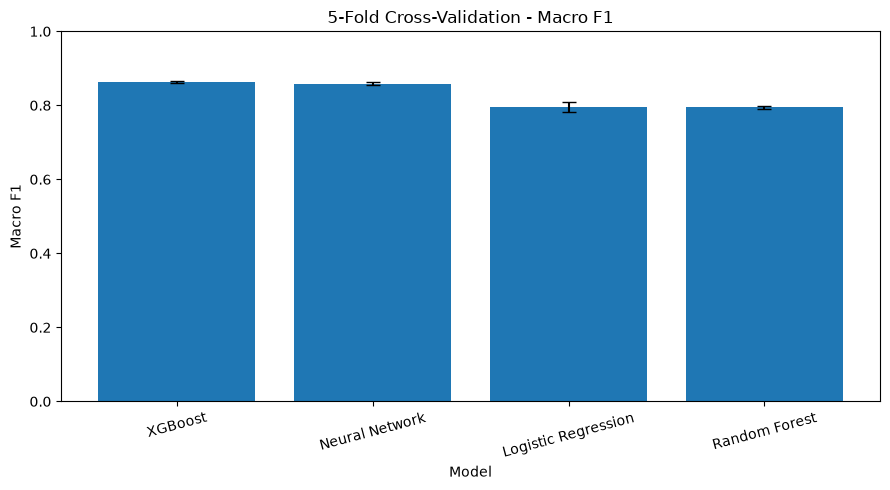

In [14]:
plt.figure(figsize=(9, 5))

plt.bar(
    cv_summary["Model"],
    cv_summary["Macro F1 Mean"],
    yerr=cv_summary["Macro F1 Std"],
    capsize=5,
)

plt.ylabel("Macro F1")
plt.xlabel("Model")
plt.title("5-Fold Cross-Validation - Macro F1")

plt.xticks(rotation=15)
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

In [15]:
from sklearn.model_selection import RandomizedSearchCV

In [16]:
xgb_tuning_model = XGBClassifier(
    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

xgb_tuning_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", xgb_tuning_model),
])

print(xgb_tuning_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['Age', 'Membership_Years',
                                                   'Login_Frequency',
                                                   'Session_Duration_Avg',
                                                   'Pages_Per_Session',
                                                   'Cart_Abandonment_Rate',
                                                   'Wishlist_Items',
                                                   'Average_Order_Value',
                                                   'Days_Since_Last_Purchase',
                                                   'Discount_Usage_Rate',
                                                   'Returns_Rate',
                                                   'Email_Open_Rate',
                                                   'Customer_Service_Calls',
       

In [17]:
param_distributions = {
    "classifier__n_estimators": [
        100, 200, 300, 400,
    ],

    "classifier__max_depth": [
        3, 4, 5, 6, 8,
    ],

    "classifier__learning_rate": [
        0.01, 0.03, 0.05, 0.1, 0.2,
    ],

    "classifier__subsample": [
        0.7, 0.8, 0.9, 1.0,
    ],

    "classifier__colsample_bytree": [
        0.7, 0.8, 0.9, 1.0,
    ],

    "classifier__min_child_weight": [
        1, 3, 5, 7,
    ],

    "classifier__gamma": [
        0, 0.1, 0.2, 0.3,
    ],
}

print("Số nhóm hyperparameter:", len(param_distributions))

for parameter, values in param_distributions.items():
    print(f"{parameter}: {values}")

Số nhóm hyperparameter: 7
classifier__n_estimators: [100, 200, 300, 400]
classifier__max_depth: [3, 4, 5, 6, 8]
classifier__learning_rate: [0.01, 0.03, 0.05, 0.1, 0.2]
classifier__subsample: [0.7, 0.8, 0.9, 1.0]
classifier__colsample_bytree: [0.7, 0.8, 0.9, 1.0]
classifier__min_child_weight: [1, 3, 5, 7]
classifier__gamma: [0, 0.1, 0.2, 0.3]


In [18]:
xgb_random_search = RandomizedSearchCV(
    estimator=xgb_tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="f1_macro",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=1,
    return_train_score=True,
    refit=True,
)

print("RandomizedSearchCV configured.")
print("Iterations :", xgb_random_search.n_iter)
print("CV folds   :", N_SPLITS)
print(
    "Total fits :",
    xgb_random_search.n_iter * N_SPLITS,
)

RandomizedSearchCV configured.
Iterations : 30
CV folds   : 5
Total fits : 150


In [19]:
print("=" * 70)
print("XGBOOST HYPERPARAMETER TUNING")
print("=" * 70)

start_time = time.time()

xgb_random_search.fit(
    X_train,
    y_train_encoded,
)

tuning_time = time.time() - start_time

print("\n" + "=" * 70)
print("TUNING COMPLETED")
print("=" * 70)
print(f"Total tuning time : {tuning_time:.2f} seconds")
print(f"Best CV Macro F1  : {xgb_random_search.best_score_:.4f}")

XGBOOST HYPERPARAMETER TUNING
Fitting 5 folds for each of 30 candidates, totalling 150 fits



TUNING COMPLETED
Total tuning time : 864.28 seconds
Best CV Macro F1  : 0.8671


In [20]:
best_params = xgb_random_search.best_params_

print("BEST PARAMETERS")
print("=" * 70)

for param, value in best_params.items():
    clean_name = param.replace(
        "classifier__", ""
    )

    print(f"{clean_name:20s}: {value}")

print(
    "\nBest CV Macro F1:",
    round(xgb_random_search.best_score_, 4),
)

BEST PARAMETERS
subsample           : 0.7
n_estimators        : 400
min_child_weight    : 3
max_depth           : 6
learning_rate       : 0.05
gamma               : 0
colsample_bytree    : 0.7

Best CV Macro F1: 0.8671


In [21]:
baseline_xgb = cv_summary[
    cv_summary["Model"] == "XGBoost"
].iloc[0]

baseline_f1 = baseline_xgb["Macro F1 Mean"]
baseline_std = baseline_xgb["Macro F1 Std"]

tuned_f1 = xgb_random_search.best_score_

improvement = tuned_f1 - baseline_f1

print("XGBOOST — BASELINE VS TUNED")
print("=" * 70)
print(
    f"Baseline Macro F1 : "
    f"{baseline_f1:.4f} ± {baseline_std:.4f}"
)
print(
    f"Tuned Macro F1    : "
    f"{tuned_f1:.4f}"
)
print(
    f"Improvement       : "
    f"{improvement:+.4f}"
)

XGBOOST — BASELINE VS TUNED
Baseline Macro F1 : 0.8626 ± 0.0021
Tuned Macro F1    : 0.8671
Improvement       : +0.0045


In [22]:
search_results = pd.DataFrame(
    xgb_random_search.cv_results_
)

top10 = (
    search_results[
        [
            "rank_test_score",
            "mean_test_score",
            "std_test_score",
            "mean_train_score",
            "params",
        ]
    ]
    .sort_values("rank_test_score")
    .head(10)
)

display(top10)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
2,1,0.867109,0.001999,0.937538,"{'classifier__subsample': 0.7, 'classifier__n_..."
1,2,0.866733,0.003222,0.891693,"{'classifier__subsample': 1.0, 'classifier__n_..."
5,3,0.866688,0.002984,0.891444,"{'classifier__subsample': 0.7, 'classifier__n_..."
7,4,0.866687,0.002252,0.890842,"{'classifier__subsample': 0.9, 'classifier__n_..."
25,5,0.866313,0.002756,0.900812,"{'classifier__subsample': 0.8, 'classifier__n_..."
28,6,0.866154,0.003547,0.911394,"{'classifier__subsample': 0.9, 'classifier__n_..."
3,7,0.866106,0.002145,0.971942,"{'classifier__subsample': 0.9, 'classifier__n_..."
18,8,0.866101,0.002519,0.944447,"{'classifier__subsample': 0.8, 'classifier__n_..."
20,9,0.866057,0.002333,0.893834,"{'classifier__subsample': 1.0, 'classifier__n_..."
0,10,0.865759,0.002876,0.984595,"{'classifier__subsample': 0.9, 'classifier__n_..."


In [23]:
top_candidates = (
    search_results
    .sort_values("rank_test_score")
    .head(4)
    .copy()
)

candidate_params = top_candidates["params"].tolist()

for i, params in enumerate(candidate_params, start=1):
    print(f"\nCandidate {i}")
    print("-" * 60)

    for key, value in params.items():
        print(
            f"{key.replace('classifier__', ''):20s}: {value}"
        )


Candidate 1
------------------------------------------------------------
subsample           : 0.7
n_estimators        : 400
min_child_weight    : 3
max_depth           : 6
learning_rate       : 0.05
gamma               : 0
colsample_bytree    : 0.7

Candidate 2
------------------------------------------------------------
subsample           : 1.0
n_estimators        : 100
min_child_weight    : 7
max_depth           : 4
learning_rate       : 0.2
gamma               : 0.1
colsample_bytree    : 0.9

Candidate 3
------------------------------------------------------------
subsample           : 0.7
n_estimators        : 400
min_child_weight    : 7
max_depth           : 4
learning_rate       : 0.05
gamma               : 0.3
colsample_bytree    : 0.8

Candidate 4
------------------------------------------------------------
subsample           : 0.9
n_estimators        : 200
min_child_weight    : 5
max_depth           : 3
learning_rate       : 0.2
gamma               : 0.1
colsample_bytree  

In [24]:
candidate_results = []

for i, params in enumerate(candidate_params, start=1):

    clean_params = {
        key.replace("classifier__", ""): value
        for key, value in params.items()
    }

    model = XGBClassifier(
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        random_state=RANDOM_STATE,
        n_jobs=-1,
        **clean_params,
    )

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model),
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train_encoded,
        cv=cv,
        scoring="f1_macro",
        return_train_score=True,
        n_jobs=1,
    )

    for fold in range(N_SPLITS):

        train_f1 = scores["train_score"][fold]
        val_f1 = scores["test_score"][fold]

        candidate_results.append({
            "Candidate": i,
            "Fold": fold + 1,
            "Train F1": train_f1,
            "Validation F1": val_f1,
            "Gap": train_f1 - val_f1,
        })

candidate_fold_df = pd.DataFrame(candidate_results)

display(candidate_fold_df.round(4))

,Candidate,Fold,Train F1,Validation F1,Gap
0,1,1,0.9359,0.8708,0.0651
1,1,2,0.9381,0.8653,0.0728
2,1,3,0.9372,0.8661,0.0711
3,1,4,0.9381,0.8658,0.0722
4,1,5,0.9384,0.8675,0.0709
5,2,1,0.8901,0.8719,0.0182
6,2,2,0.8922,0.8669,0.0253
7,2,3,0.8927,0.8667,0.0259
8,2,4,0.8920,0.8617,0.0302
9,2,5,0.8916,0.8664,0.0252


In [25]:
candidate_summary = (
    candidate_fold_df
    .groupby("Candidate")
    .agg({
        "Train F1": ["mean", "std"],
        "Validation F1": ["mean", "std"],
        "Gap": ["mean", "std"],
    })
)

display(candidate_summary.round(4))

comparison_rows = []

for candidate in sorted(
    candidate_fold_df["Candidate"].unique()
):

    temp = candidate_fold_df[
        candidate_fold_df["Candidate"] == candidate
    ]

    comparison_rows.append({
        "Candidate": candidate,
        "Train F1 Mean": temp["Train F1"].mean(),
        "Validation F1 Mean": temp["Validation F1"].mean(),
        "Validation F1 Std": temp["Validation F1"].std(),
        "Train-Val Gap": temp["Gap"].mean(),
    })

candidate_comparison = pd.DataFrame(
    comparison_rows
)

display(candidate_comparison.round(4))

Train F1         Validation F1             Gap        
              mean     std          mean     std    mean     std
Candidate                                                       
1           0.9375  0.0010        0.8671  0.0022  0.0704  0.0031
2           0.8917  0.0010        0.8667  0.0036  0.0250  0.0043
3           0.8914  0.0011        0.8667  0.0033  0.0248  0.0041
4           0.8908  0.0011        0.8667  0.0025  0.0242  0.0036

,Candidate,Train F1 Mean,Validation F1 Mean,Validation F1 Std,Train-Val Gap
0,1,0.9375,0.8671,0.0022,0.0704
1,2,0.8917,0.8667,0.0036,0.0250
2,3,0.8914,0.8667,0.0033,0.0248
3,4,0.8908,0.8667,0.0025,0.0242


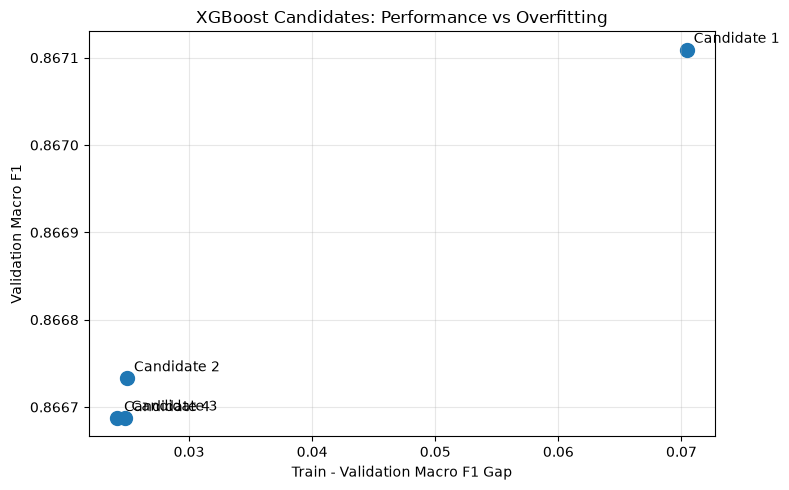

In [26]:
plt.figure(figsize=(8, 5))

plt.scatter(
    candidate_comparison["Train-Val Gap"],
    candidate_comparison["Validation F1 Mean"],
    s=100,
)

for _, row in candidate_comparison.iterrows():
    plt.annotate(
        f"Candidate {int(row['Candidate'])}",
        (
            row["Train-Val Gap"],
            row["Validation F1 Mean"],
        ),
        xytext=(5, 5),
        textcoords="offset points",
    )

plt.xlabel("Train - Validation Macro F1 Gap")
plt.ylabel("Validation Macro F1")
plt.title(
    "XGBoost Candidates: Performance vs Overfitting"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Final Model Selection

Sau quá trình Hyperparameter Tuning và đánh giá các cấu hình bằng
5-Fold Stratified Cross-Validation, Candidate 4 được lựa chọn làm
mô hình XGBoost cuối cùng.

Mặc dù Candidate 1 đạt Macro F1 trung bình cao nhất (0.8671),
mức chênh lệch so với Candidate 4 là rất nhỏ. Candidate 4 đạt
Macro F1 khoảng 0.8667, đồng thời có độ lệch chuẩn thấp và khoảng
cách giữa Train F1 và Validation F1 nhỏ hơn đáng kể.

Do đó, Candidate 4 được ưu tiên nhằm cân bằng giữa hiệu năng,
độ ổn định và khả năng tổng quát hóa của mô hình.

Từ thời điểm này, cấu hình mô hình được cố định trước khi đánh giá
trên tập test.

In [27]:
FINAL_XGB_PARAMS = {
    "n_estimators": 200,
    "max_depth": 3,
    "learning_rate": 0.2,
    "subsample": 0.9,
    "colsample_bytree": 1.0,
    "min_child_weight": 5,
    "gamma": 0.1,
}

final_xgb = XGBClassifier(
    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    **FINAL_XGB_PARAMS,
)

final_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", final_xgb),
])

print("Final XGBoost configuration:")
for key, value in FINAL_XGB_PARAMS.items():
    print(f"{key:20s}: {value}")

Final XGBoost configuration:
n_estimators        : 200
max_depth           : 3
learning_rate       : 0.2
subsample           : 0.9
colsample_bytree    : 1.0
min_child_weight    : 5
gamma               : 0.1


In [28]:
print("=" * 70)
print("TRAINING FINAL XGBOOST MODEL")
print("=" * 70)

start_time = time.time()

final_pipeline.fit(
    X_train,
    y_train_encoded,
)

final_training_time = time.time() - start_time

print("\nTraining completed.")
print(
    f"Training time: "
    f"{final_training_time:.2f} seconds"
)
print(
    f"Training samples: "
    f"{len(X_train):,}"
)

TRAINING FINAL XGBOOST MODEL



Training completed.
Training time: 3.18 seconds
Training samples: 39,968


In [29]:
y_test_encoded = y_test.map(class_to_int)

print("Test samples:", len(X_test))
print(
    "Missing encoded labels:",
    y_test_encoded.isna().sum(),
)

start_time = time.time()

y_pred = final_pipeline.predict(X_test)

prediction_time = time.time() - start_time

print(
    f"Prediction time: "
    f"{prediction_time:.4f} seconds"
)
print(
    "Predictions:",
    len(y_pred),
)

Test samples: 9992
Missing encoded labels: 0
Prediction time: 0.0662 seconds
Predictions: 9992


In [30]:
final_accuracy = accuracy_score(
    y_test_encoded,
    y_pred,
)

final_precision = precision_score(
    y_test_encoded,
    y_pred,
    average="macro",
    zero_division=0,
)

final_recall = recall_score(
    y_test_encoded,
    y_pred,
    average="macro",
    zero_division=0,
)

final_f1 = f1_score(
    y_test_encoded,
    y_pred,
    average="macro",
    zero_division=0,
)

print("=" * 70)
print("FINAL TEST RESULTS")
print("=" * 70)
print(f"Accuracy        : {final_accuracy:.4f}")
print(f"Macro Precision : {final_precision:.4f}")
print(f"Macro Recall    : {final_recall:.4f}")
print(f"Macro F1        : {final_f1:.4f}")

FINAL TEST RESULTS
Accuracy        : 0.8748
Macro Precision : 0.8729
Macro Recall    : 0.8714
Macro F1        : 0.8718


In [31]:
from sklearn.metrics import classification_report


print(
    classification_report(
        y_test_encoded,
        y_pred,
        labels=[0, 1, 2],
        target_names=CLASS_ORDER,
        digits=4,
        zero_division=0,
    )
)

              precision    recall  f1-score   support

         Low     0.9149    0.9137    0.9143      3791
      Medium     0.7808    0.8179    0.7989      3026
        High     0.9229    0.8825    0.9023      3175

    accuracy                         0.8748      9992
   macro avg     0.8729    0.8714    0.8718      9992
weighted avg     0.8768    0.8748    0.8755      9992



Confusion Matrix:
[[3464  327    0]
 [ 317 2475  234]
 [   5  368 2802]]


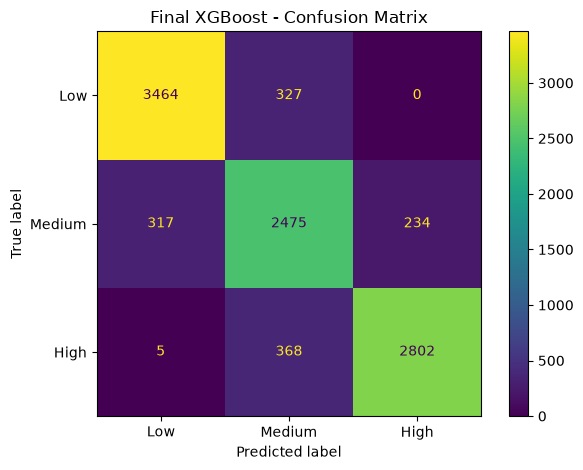

In [32]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
)


cm = confusion_matrix(
    y_test_encoded,
    y_pred,
    labels=[0, 1, 2],
)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_ORDER,
)

disp.plot(
    values_format="d"
)

plt.title(
    "Final XGBoost - Confusion Matrix"
)

plt.tight_layout()
plt.show()

In [33]:
selected_cv_f1 = (
    candidate_comparison
    .loc[
        candidate_comparison["Candidate"] == 4,
        "Validation F1 Mean",
    ]
    .iloc[0]
)

generalization_gap = (
    selected_cv_f1 - final_f1
)

final_comparison = pd.DataFrame({
    "Evaluation": [
        "5-Fold CV",
        "Final Test",
    ],
    "Macro F1": [
        selected_cv_f1,
        final_f1,
    ],
})

display(final_comparison.round(4))

print(
    f"CV Macro F1       : "
    f"{selected_cv_f1:.4f}"
)
print(
    f"Final Test F1     : "
    f"{final_f1:.4f}"
)
print(
    f"CV - Test Gap     : "
    f"{generalization_gap:+.4f}"
)

,Evaluation,Macro F1
0,5-Fold CV,0.8667
1,Final Test,0.8718


CV Macro F1       : 0.8667
Final Test F1     : 0.8718
CV - Test Gap     : -0.0052


In [34]:
import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "purchase_level_xgboost_pipeline.joblib"

joblib.dump(final_pipeline, MODEL_PATH)

print("Model saved successfully.")
print("Path:", MODEL_PATH.resolve())

Model saved successfully.
Path: models\purchase_level_xgboost_pipeline.joblib


In [35]:
import json


metadata = {
    "model_name": "XGBoost",
    "task": "Purchase Level Classification",

    "class_mapping": {
        "0": "Low",
        "1": "Medium",
        "2": "High",
    },

    "target": "Purchase_Level",

    "excluded_features": [
        "Total_Purchases",
    ],

    "input_features": X_train.columns.tolist(),

    "hyperparameters": FINAL_XGB_PARAMS,

    "cv_macro_f1": round(
        float(selected_cv_f1), 6
    ),

    "test_metrics": {
        "accuracy": round(
            float(final_accuracy), 6
        ),
        "macro_precision": round(
            float(final_precision), 6
        ),
        "macro_recall": round(
            float(final_recall), 6
        ),
        "macro_f1": round(
            float(final_f1), 6
        ),
    },

    "random_state": RANDOM_STATE,
}

METADATA_PATH = (
    MODEL_DIR /
    "purchase_level_xgboost_metadata.json"
)

with open(
    METADATA_PATH,
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        metadata,
        f,
        ensure_ascii=False,
        indent=4,
    )

print("Metadata saved successfully.")
print("Path:", METADATA_PATH.resolve())

Metadata saved successfully.
Path: models\purchase_level_xgboost_metadata.json


In [36]:
loaded_pipeline = joblib.load(
    MODEL_PATH
)

loaded_predictions = loaded_pipeline.predict(
    X_test
)

same_predictions = np.array_equal(
    y_pred,
    loaded_predictions,
)

print(
    "Loaded model predictions identical:",
    same_predictions,
)

Loaded model predictions identical: True


In [37]:
sample = X_test.iloc[[0]]

sample_prediction = loaded_pipeline.predict(
    sample
)[0]

sample_probability = loaded_pipeline.predict_proba(
    sample
)[0]

predicted_label = class_to_int.copy()
int_to_class = {
    value: key
    for key, value in class_to_int.items()
}

print(
    "Prediction:",
    int_to_class[int(sample_prediction)],
)

print("\nProbabilities:")

for class_id, probability in enumerate(
    sample_probability
):
    print(
        f"{int_to_class[class_id]:6s}: "
        f"{probability:.4f}"
    )

Prediction: High

Probabilities:
Low   : 0.0000
Medium: 0.0342
High  : 0.9658


## Kết luận

Trong notebook này, bốn mô hình Logistic Regression, Random Forest,
XGBoost và Neural Network được đánh giá bằng Stratified 5-Fold
Cross-Validation.

XGBoost cho kết quả tốt nhất trong nhóm mô hình baseline. Sau quá
trình Hyperparameter Tuning và phân tích khả năng tổng quát hóa,
một cấu hình XGBoost có mức cân bằng tốt giữa hiệu năng và độ ổn
định được lựa chọn.

Mô hình cuối cùng đạt Accuracy 0.8748 và Macro F1 0.8718 trên tập
test. Trong ba lớp, Low và High được dự đoán tốt hơn, trong khi
Medium là lớp khó phân loại nhất và thường bị nhầm với hai lớp
lân cận.

Pipeline cuối cùng bao gồm cả bước tiền xử lý dữ liệu và mô hình
XGBoost đã được lưu để phục vụ cho quá trình tích hợp vào ứng dụng.